# 07 - Comparing the four models and their mistakes

Uses the validation predictions saved by notebooks 02-05 (the best configuration of each model).
1. the results table (validation accuracy of every method on both tasks)
2. sentiment: per-class scores, is **Neutral** the hardest class?
3. images: which classes are hard, which get confused with each other?
4. do the models make the **same mistakes**, and does the network fix the others' mistakes?
5. how confident is the network when it is wrong?
6. training / prediction time

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix, f1_score   # metrics only

from src.data import get_split, SENTIMENT_NAMES
from src.utils import COLORS, MODEL_NAMES, accuracy, save_table, save_figure, load_predictions, TABLE_DIR

TASKS = ("image", "sentiment")
y_val = {task: get_split(task)[3] for task in TASKS}
pred, proba, info = {}, {}, {}
for task in TASKS:
    for m in MODEL_NAMES:
        pred[(task, m)], proba[(task, m)], info[(task, m)] = load_predictions(task, m)

## 1. Results table

In [2]:
rows = []
for m, name in MODEL_NAMES.items():
    row = dict(method=name)
    for task in TASKS:
        row[f"{task} val acc"] = accuracy(y_val[task], pred[(task, m)])
        row[f"{task} macro-F1"] = f1_score(y_val[task], pred[(task, m)], average="macro")
    rows.append(row)
results = pd.DataFrame(rows)
save_table(results, "results_validation")
results.round(4)

,method,image val acc,image macro-F1,sentiment val acc,sentiment macro-F1
0,k-NN,0.6148,0.6152,0.5933,0.5788
1,Decision Tree,0.1192,0.1108,0.4896,0.4882
2,Random Forest,0.3662,0.3497,0.6029,0.6007
3,Neural Network,0.3872,0.3853,0.6812,0.6789


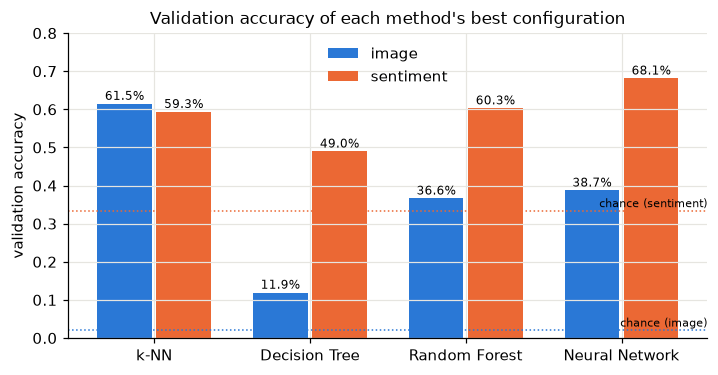

In [3]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
x = np.arange(len(MODEL_NAMES))
width = 0.38
for j, task in enumerate(TASKS):
    values = results[f"{task} val acc"].to_numpy()
    positions = x + (j - 0.5) * width
    ax.bar(positions, values, width=width - 0.03, color=COLORS[j], label=task)
    for xi, v in zip(positions, values):
        ax.text(xi, v + 0.01, f"{v:.1%}", ha="center", fontsize=8)
ax.axhline(1 / 50, color=COLORS[0], linestyle=":", linewidth=1)
ax.axhline(1 / 3, color=COLORS[1], linestyle=":", linewidth=1)
ax.text(3.55, 1 / 50 + 0.01, "chance (image)", fontsize=7, ha="right")
ax.text(3.55, 1 / 3 + 0.01, "chance (sentiment)", fontsize=7, ha="right")
ax.set_xticks(x)
ax.set_xticklabels(MODEL_NAMES.values())
ax.set_ylabel("validation accuracy")
ax.set_ylim(0, 0.8)
ax.set_title("Validation accuracy of each method's best configuration")
ax.legend()
save_figure(fig, "07_summary_accuracy")
plt.show()

**The ranking flips between the two tasks.**
* Images: **k-NN 61.5%** >> Neural Network 38.7% > Random Forest 36.6% >> Decision Tree 11.9% (chance 2%).
* Sentiment: **Neural Network 68.1%** > Random Forest 60.3% ~ k-NN 59.3% >> Decision Tree 49.0% (chance 33%).

k-NN wins on the image histograms because each class is made of small groups of near-relatives
(notebook 02). The network wins on the BERT embeddings, where sentiment is spread thinly over many
dimensions and a learned combination of all features beats voting among neighbours. The decision
tree is last on both: one feature per question is a poor fit for both kinds of features.

These are the best settings found *on this validation set*, so they are slightly optimistic.
For the network the 5-seed means are 38.6% (image) and 68.1% (sentiment).

## 2. Sentiment: is Neutral the hardest class?

In [4]:
rows = []
for m, name in MODEL_NAMES.items():
    p, r, f, _ = precision_recall_fscore_support(y_val["sentiment"], pred[("sentiment", m)], labels=[0, 1, 2])
    for c in range(3):
        rows.append(dict(model=name, label=SENTIMENT_NAMES[c], precision=p[c], recall=r[c], f1=f[c]))
per_class = pd.DataFrame(rows)
save_table(per_class, "sentiment_per_class")
per_class.round(3)

,model,label,precision,recall,f1
0,k-NN,Negative,0.590,0.749,0.660
1,k-NN,Neutral,0.626,0.350,0.449
2,k-NN,Positive,0.581,0.681,0.627
3,Decision Tree,Negative,0.533,0.582,0.557
4,Decision Tree,Neutral,0.440,0.456,0.448
5,Decision Tree,Positive,0.494,0.430,0.460
6,Random Forest,Negative,0.625,0.705,0.663
7,Random Forest,Neutral,0.550,0.506,0.527
8,Random Forest,Positive,0.628,0.598,0.612
9,Neural Network,Negative,0.709,0.782,0.744


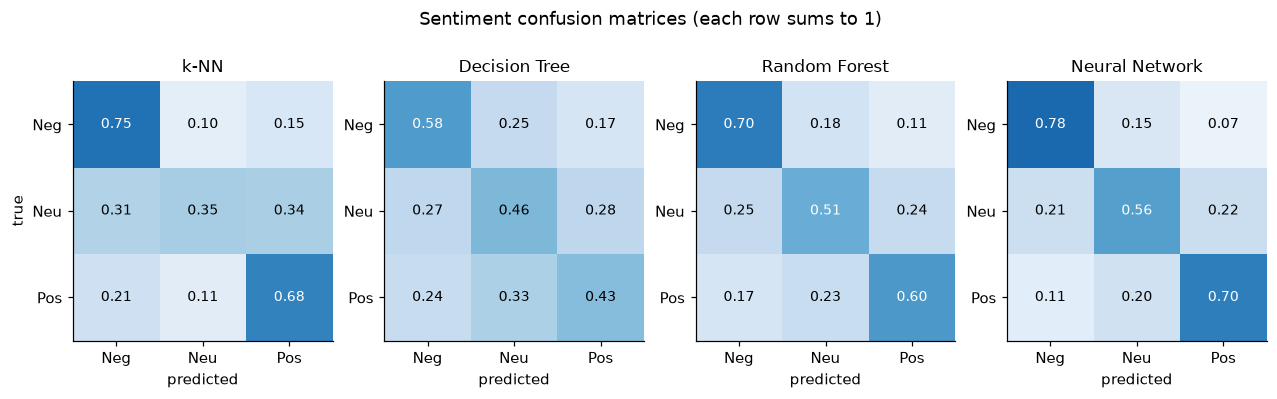

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
for ax, (m, name) in zip(axes, MODEL_NAMES.items()):
    cm = confusion_matrix(y_val["sentiment"], pred[("sentiment", m)], labels=[0, 1, 2])
    share = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(share, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{share[i, j]:.2f}", ha="center", va="center", fontsize=9,
                    color="white" if share[i, j] > .5 else "black")
    ax.set_xticks(range(3))
    ax.set_xticklabels(["Neg", "Neu", "Pos"])
    ax.set_yticks(range(3))
    ax.set_yticklabels(["Neg", "Neu", "Pos"])
    ax.set_xlabel("predicted")
    ax.set_title(name)
    ax.grid(False)
axes[0].set_ylabel("true")
fig.suptitle("Sentiment confusion matrices (each row sums to 1)", y=1.03)
save_figure(fig, "07_sentiment_confusion")
plt.show()

**Yes, Neutral is the hardest class for every model** (lowest F1 for all four, 0.45-0.59). Most
mistakes involve Neutral: the network labels 22% of Neutral tweets as Negative and another 22% as
Positive, while Negative -> Positive mistakes are rare (7%). k-NN is especially bad at Neutral
(recall 35%, it predicts Neutral for only 447 of 2,400 tweets): Neutral tweets sit *between* the
other two (notebook 01), so a neutral tweet's neighbours are often mostly negative or mostly positive.

## 3. Images: which classes are hard, and which get confused?

In [6]:
per_class_img = pd.DataFrame({name: [np.mean(pred[("image", m)][y_val["image"] == c] == c) for c in range(50)]
                              for m, name in MODEL_NAMES.items()})
per_class_img.index.name = "class"
order = per_class_img["k-NN"].sort_values()
print("hardest classes for k-NN:")
print(per_class_img.loc[order.index[:5]].round(2))
print("\neasiest classes for k-NN:")
print(per_class_img.loc[order.index[-5:]].round(2))
print("\ndo the models find the same classes hard? (rank correlation of per-class accuracy)")
print(per_class_img.corr(method="spearman").round(2))

hardest classes for k-NN:
       k-NN  Decision Tree  Random Forest  Neural Network
class                                                    
29     0.44           0.05           0.15            0.24
22     0.45           0.02           0.08            0.22
9      0.48           0.01           0.19            0.21
27     0.48           0.01           0.18            0.29
40     0.48           0.05           0.16            0.24

easiest classes for k-NN:
       k-NN  Decision Tree  Random Forest  Neural Network
class                                                    
18     0.76           0.16           0.56            0.55
25     0.80           0.24           0.70            0.56
13     0.81           0.26           0.69            0.60
46     0.82           0.52           0.69            0.70
48     0.84           0.36           0.70            0.66

do the models find the same classes hard? (rank correlation of per-class accuracy)
                k-NN  Decision Tree  Random Forest 

In [7]:
def most_confused(m, n):
    cm = confusion_matrix(y_val["image"], pred[("image", m)], labels=range(50))
    both = cm + cm.T
    upper = np.triu_indices(50, k=1)
    df = pd.DataFrame(dict(class_a=upper[0], class_b=upper[1], confusions=both[upper],
                           a_predicted_as_b=cm[upper], b_predicted_as_a=cm.T[upper]))
    return df.sort_values("confusions", ascending=False).head(n)

confused = most_confused("knn", 10)
top30 = {name: set(map(tuple, most_confused(m, 30)[["class_a", "class_b"]].to_numpy()))
         for m, name in MODEL_NAMES.items()}
kmeans_pairs = pd.read_csv(TABLE_DIR / "kmeans_image_coclustered_pairs.csv").head(30)
top30["k-Means"] = set(map(tuple, kmeans_pairs[["class_a", "class_b"]].to_numpy()))
for name in ("Random Forest", "Neural Network", "k-Means"):
    confused[f"also in {name} top 30"] = [(a, b) in top30[name] for a, b in zip(confused.class_a, confused.class_b)]
print("most confused class pairs for k-NN (80 validation images per class):")
confused

most confused class pairs for k-NN (80 validation images per class):


,class_a,class_b,confusions,a_predicted_as_b,b_predicted_as_a,also in Random Forest top 30,also in Neural Network top 30,also in k-Means top 30
1148,37,39,11,9,2,True,True,True
1035,30,31,9,3,6,False,True,True
97,2,3,9,1,8,True,True,True
791,20,22,9,3,6,True,True,True
322,7,8,9,5,4,True,False,True
98,2,4,8,3,5,True,True,True
523,12,14,8,4,4,True,False,True
1159,38,39,8,4,4,False,False,False
28,0,29,7,2,5,False,False,False
445,10,11,7,2,5,True,True,False


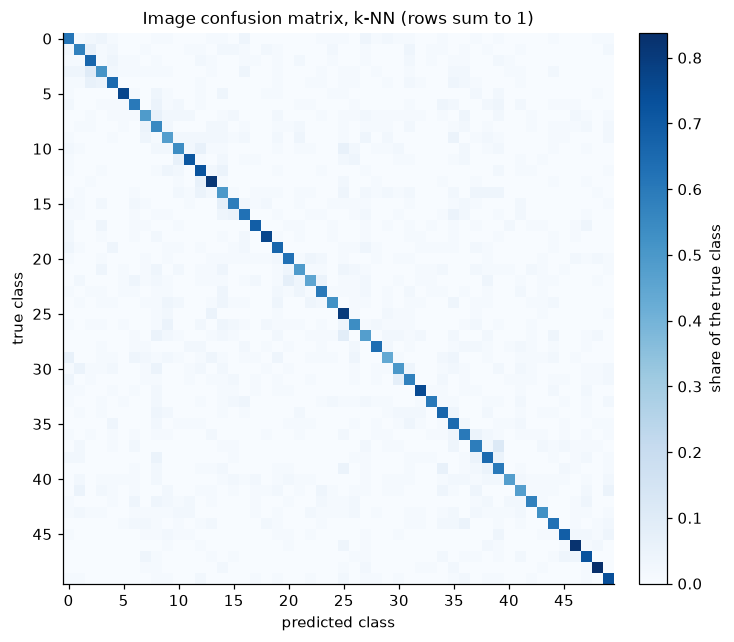

In [8]:
cm = confusion_matrix(y_val["image"], pred[("image", "knn")], labels=range(50))
share = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(share, cmap="Blues", vmin=0, vmax=share.max())
ax.set_xlabel("predicted class")
ax.set_ylabel("true class")
ax.set_xticks(range(0, 50, 5))
ax.set_yticks(range(0, 50, 5))
ax.grid(False)
ax.set_title("Image confusion matrix, k-NN (rows sum to 1)")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="share of the true class")
save_figure(fig, "07_image_confusion")
plt.show()

* **The models agree on which classes are hard** (rank correlation of per-class accuracy 0.67-0.86).
  Hardest for k-NN: classes 29, 22, 9, 27, 40 (44-48%); easiest: 48, 46, 13, 25 (80-84%). We only
  have class numbers, not object names.
* **The most confused pairs are genuinely close in feature space:** 7 of k-NN's 10 most confused
  pairs are also among the 30 pairs k-Means puts together most often (notebook 06), and most are
  confused by the forest and the network too. The worst is 37 <-> 39 (37 predicted as 39 nine times).
* Confusions are spread out: no pair is mixed up more than 11 times out of 160 images. (With cosine
  distance, class 2 used to attract many images of classes 3 and 4; intersection reduced this,
  and k-NN now predicts every class between 49 and 116 times, for 80 true images each.)

## 4. Do the models make the same mistakes?

In [9]:
for task in TASKS:
    wrong = pd.DataFrame({name: pred[(task, m)] != y_val[task] for m, name in MODEL_NAMES.items()})
    n_wrong = wrong.sum(axis=1)
    print(f"=== {task} ({len(wrong)} validation examples) ===")
    print("  all 4 models right: %5.1f%%" % (100 * (n_wrong == 0).mean()))
    print("  all 4 models wrong: %5.1f%%" % (100 * (n_wrong == 4).mean()))
    print("  if the 4 models were independent, 'all wrong' would be %.1f%%\n" % (100 * np.prod(wrong.mean())))

=== image (4000 validation examples) ===
  all 4 models right:   7.6%
  all 4 models wrong:  28.4%
  if the 4 models were independent, 'all wrong' would be 13.2%

=== sentiment (2400 validation examples) ===
  all 4 models right:  30.0%
  all 4 models wrong:  15.5%
  if the 4 models were independent, 'all wrong' would be 2.6%



In [10]:
rows = []
for task in TASKS:
    nn_right = pred[(task, "nn")] == y_val[task]
    for m in ("knn", "dt", "rf"):
        wrong = pred[(task, m)] != y_val[task]
        rows.append(dict(task=task, other_model=MODEL_NAMES[m], its_mistakes=int(wrong.sum()),
                         nn_fixes=nn_right[wrong].mean(), nn_breaks=(~nn_right[~wrong]).mean()))
print("nn_fixes  = share of that model's mistakes the network gets right")
print("nn_breaks = share of that model's correct answers the network gets wrong")
pd.DataFrame(rows).round(3)

nn_fixes  = share of that model's mistakes the network gets right
nn_breaks = share of that model's correct answers the network gets wrong


,task,other_model,its_mistakes,nn_fixes,nn_breaks
0,image,k-NN,1541,0.165,0.474
1,image,Decision Tree,3523,0.341,0.270
2,image,Random Forest,2535,0.222,0.328
3,sentiment,k-NN,976,0.423,0.142
4,sentiment,Decision Tree,1225,0.572,0.205
5,sentiment,Random Forest,953,0.365,0.111


**Largely yes, the mistakes are shared.** 28.4% of validation images are missed by all four models,
more than twice the 13.2% we would expect if their errors were independent; on sentiment it is
15.5% vs 2.6%. Some examples are hard for *any* model on these features (ambiguous tweets, unusual
photos), which also limits what combining models can do.

* **Sentiment: the network really fixes mistakes.** It gets right 42% of k-NN's mistakes and 37% of
  the forest's, while breaking only 11-14% of their correct answers.
* **Images: not compared with k-NN.** The network fixes only 17% of k-NN's mistakes but gets 47% of
  k-NN's correct answers wrong. That is why averaging the two scores *below* k-NN alone (notebook 08).

## 5. How confident is the network when it is wrong?

In [11]:
rows = []
for task in TASKS:
    p = proba[(task, "nn")]
    confidence = p.max(axis=1)
    right = p.argmax(axis=1) == y_val[task]
    for lo, hi in ((0, .4), (.4, .6), (.6, .8), (.8, .95), (.95, 1.01)):
        m = (confidence >= lo) & (confidence < hi)
        rows.append(dict(task=task, confidence=f"{lo:.2f}-{min(hi, 1):.2f}", share_of_examples=m.mean(),
                         accuracy=right[m].mean() if m.any() else np.nan))
pd.DataFrame(rows).round(3)

,task,confidence,share_of_examples,accuracy
0,image,0.00-0.40,0.050,0.111
1,image,0.40-0.60,0.154,0.190
2,image,0.60-0.80,0.182,0.242
3,image,0.80-0.95,0.212,0.304
4,image,0.95-1.00,0.403,0.606
5,sentiment,0.00-0.40,0.020,0.417
6,sentiment,0.40-0.60,0.321,0.539
7,sentiment,0.60-0.80,0.401,0.684
8,sentiment,0.80-0.95,0.212,0.857
9,sentiment,0.95-1.00,0.046,0.955


On sentiment the confidence means something: above 0.95 the network is right 96% of the time, below
0.6 only about 53%. On images the network is **over-confident**: 40% of its predictions have
confidence >= 0.95 but only 61% of those are right, a typical sign of a network that has memorized
its training set.

## 6. Computational cost (approximate, same machine)

In [12]:
rows = []
for task in TASKS:
    for m, name in MODEL_NAMES.items():
        rows.append(dict(task=task, model=name, fit_seconds=info[(task, m)].get("fit_seconds"),
                         predict_seconds=info[(task, m)].get("predict_seconds")))
pd.DataFrame(rows).round(2)

,task,model,fit_seconds,predict_seconds
0,image,k-NN,0.03,9.12
1,image,Decision Tree,6.15,0.00
2,image,Random Forest,554.84,3.58
3,image,Neural Network,229.80,0.15
4,sentiment,k-NN,0.04,0.45
5,sentiment,Decision Tree,1.81,0.00
6,sentiment,Random Forest,112.61,0.88
7,sentiment,Neural Network,25.55,0.05


Only the order of magnitude matters here. k-NN has no training cost but pays at prediction time
(distances to every training row; intersection is slower than cosine). The Random Forest is by far
the most expensive to train (400 trees in pure NumPy). The network is moderate to train and almost
free to use. The single tree is cheap but weak.